In [1]:
from collections import Counter

from bci import config, plot
from bci.preprocessing import bandpass, erd_percent, load_block, task_epochs

In [2]:
BLOCK_PATH = config.SOURCEDATA_DIR / "sub-p001/ses-2/eeg/sub-p001_ses-2_task-calibration_run-001_eeg.xdf"
MU_BAND_HZ = (8.0, 13.0)
FILTER_ORDER = 4
# times relative to the TASK marker: reference inside the fixation, activity inside the imagery
EPOCH_START_S = -3.0
EPOCH_END_S = 3.75
REFERENCE_WINDOW_S = (-3.0, -1.5)
ACTIVITY_WINDOW_S = (0.5, 3.5)

In [3]:
eeg, eeg_times, marker_codes, marker_times = load_block(BLOCK_PATH)
# filter the continuous signal before cutting: no filter transients inside the epochs
mu_eeg = bandpass(eeg, config.EEG_SAMPLING_RATE_HZ, MU_BAND_HZ[0], MU_BAND_HZ[1], FILTER_ORDER)
epochs, labels, epoch_times_s = task_epochs(mu_eeg, eeg_times, marker_codes, marker_times,
                                            EPOCH_START_S, EPOCH_END_S)
erd = erd_percent(epochs, epoch_times_s, REFERENCE_WINDOW_S, ACTIVITY_WINDOW_S)
print(f"{len(labels)} epochs: {dict(Counter(labels.tolist()))}")

12 epochs: {'right': 5, 'rest': 2, 'left': 5}


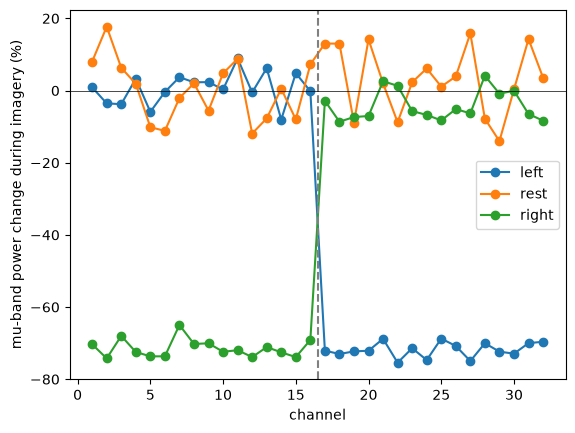

In [4]:
plot.plot_erd(erd, labels)